# 01 — States and phase space

The building blocks: Gaussian state constructors, the mean/covariance
representation, choosing ħ, and the three phase-space quasiprobability
functions (Wigner, Husimi Q, Glauber-Sudarshan P).

See `docs/conventions.md` for the full formalism behind everything below.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvcircuit as cv

np.set_printoptions(precision=4, suppress=True)

## Constructors

Every state is a `GaussianState`: a mean vector and covariance matrix in
**xpxp** order, plus the value of ħ used to define x, p. The default is
`hbar=2` (vacuum covariance = identity, "shot-noise units").

In [2]:
vac = cv.vacuum(1)
print(vac)
print("mean:", vac.mean)
print("cov:\n", vac.cov)

GaussianState(1 mode(s), hbar=2, purity=1)
mean: [0. 0.]
cov:
 [[1. 0.]
 [0. 1.]]


In [3]:
coh = cv.coherent(1.5 + 0.8j)
sq = cv.squeezed(r=0.8, phi=0.0)
th = cv.thermal(nbar=0.7)

for name, s in [("coherent", coh), ("squeezed", sq), ("thermal", th)]:
    print(f"{name:10s}  mean_photon_number={s.mean_photon_number():.3f}  "
          f"purity={s.purity():.3f}  is_classical={s.is_classical()}")

coherent    mean_photon_number=2.890  purity=1.000  is_classical=True
squeezed    mean_photon_number=0.789  purity=1.000  is_classical=False
thermal     mean_photon_number=0.700  purity=0.417  is_classical=True


## Choosing ħ

ħ is a keyword on every constructor. `hbar=2` (default) gives vacuum
covariance = 𝟙; `hbar=1` gives the theory-literature convention (vacuum =
½𝟙), matching Brask's reference note and much of the CV quantum
information literature. Physical, ħ-independent quantities — like
squeezing in dB, or purity — agree between the two; only the raw numbers
in `mean`/`cov` differ.

In [4]:
r = 0.8
s_hbar2 = cv.squeezed(r, hbar=2)
s_hbar1 = cv.squeezed(r, hbar=1)

print("hbar=2 cov:\n", s_hbar2.cov)
print("hbar=1 cov:\n", s_hbar1.cov)
print()
print("squeezing (dB), hbar=2:", s_hbar2.squeezing_db(0))
print("squeezing (dB), hbar=1:", s_hbar1.squeezing_db(0))

hbar=2 cov:
 [[0.2019 0.    ]
 [0.     4.953 ]]
hbar=1 cov:
 [[0.1009 0.    ]
 [0.     2.4765]]

squeezing (dB), hbar=2: -6.948711710452027
squeezing (dB), hbar=1: -6.948711710452027


## Combining and reducing states

`&` takes a tensor product; `.reduced(modes)` is a partial trace.

In [5]:
joint = cv.squeezed(0.6) & cv.coherent(1 + 1j) & cv.thermal(0.4)
print(joint)
print("just the coherent mode:", joint.reduced([1]))

GaussianState(3 mode(s), hbar=2, purity=0.5556)
just the coherent mode: GaussianState(1 mode(s), hbar=2, purity=1)


## Wigner, Husimi Q, and Glauber-Sudarshan P

All three are special cases of the *s*-ordered quasiprobability
distribution, `state.quasiprobability(x, p, s=...)`: `s=0` is Wigner
(can go negative for non-Gaussian states — always non-negative for the
Gaussian states this library builds), `s=-1` is Husimi Q (always a proper
probability distribution — it's Wigner convolved with vacuum noise, hence
visibly wider below), and `s=+1` is the P function (only a genuine
function for *classical* states — `is_classical()` checks this, and
`p_function()` raises a clear error otherwise).

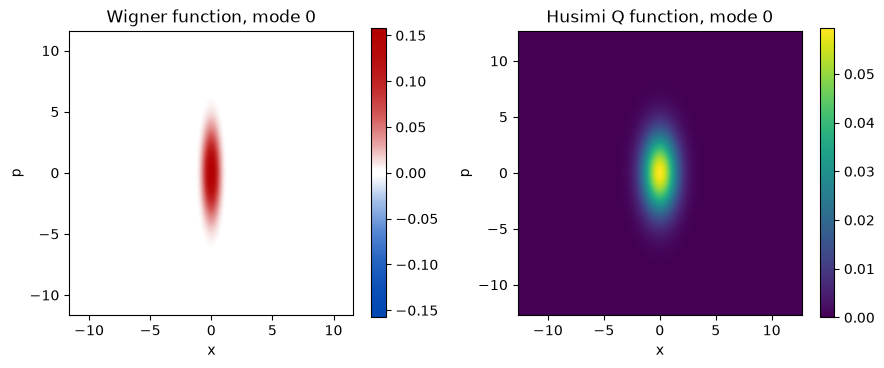

In [6]:
squeezed_state = cv.squeezed(0.8)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
cv.visualization.plot_wigner(squeezed_state, ax=axes[0])
cv.visualization.plot_husimi(squeezed_state, ax=axes[1])
fig.tight_layout()

squeezed state is_classical: False
raised as expected: the s=1.0 quasiprobability is not a valid function for this state (cov - s*hbar/2*I is not positive definite); this always happens for s=1 (the P function) unless the state is classical (see is_classical())

thermal state is_classical: True


<Axes: title={'center': 'P function, mode 0'}, xlabel='x', ylabel='p'>

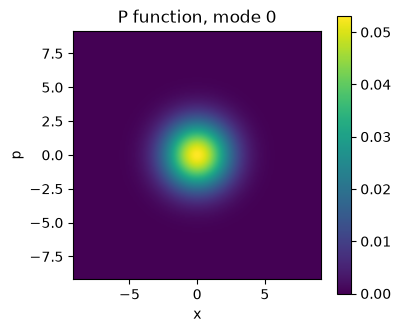

In [7]:
# the P function requires a classical state -- a squeezed state isn't one
print("squeezed state is_classical:", squeezed_state.is_classical())
try:
    squeezed_state.p_function(0.0, 0.0)
except ValueError as exc:
    print("raised as expected:", exc)

thermal_state = cv.thermal(1.5)
print("\nthermal state is_classical:", thermal_state.is_classical())
fig, ax = plt.subplots(figsize=(4, 3.6))
cv.visualization.plot_p(thermal_state, ax=ax)

## Marginals and uncertainty ellipses

`plot_marginal` shows the 1-D probability density of any quadrature
(homodyne angle); `plot_ellipse` overlays 1σ uncertainty ellipses, useful
for comparing several states at a glance.

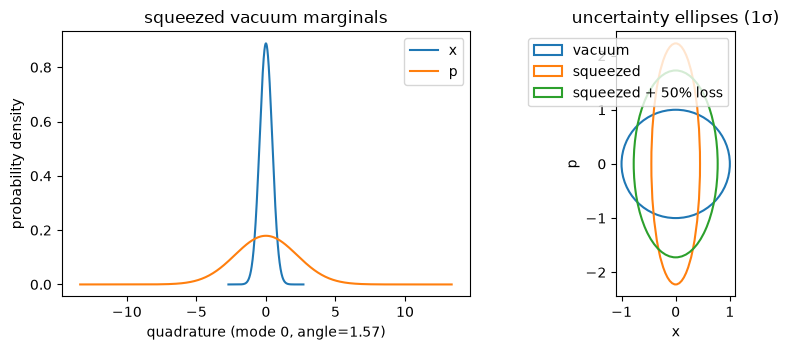

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))

for angle, label in [(0.0, "x"), (np.pi / 2, "p")]:
    cv.visualization.plot_marginal(squeezed_state, mode=0, angle=angle, ax=axes[0], label=label)
axes[0].set_title("squeezed vacuum marginals")

cv.visualization.plot_ellipse(
    [cv.vacuum(1), cv.squeezed(0.8), cv.squeezed(0.8).loss(0.5)],
    mode=0, ax=axes[1], labels=["vacuum", "squeezed", "squeezed + 50% loss"],
)
axes[1].set_title("uncertainty ellipses (1σ)")
fig.tight_layout()

## Symplectic eigenvalues, purity, entropy

Every state's covariance has a Williamson decomposition into symplectic
eigenvalues ν̄ₖ (shot-noise units, vacuum = 1); purity and von Neumann
entropy are simple closed forms in terms of them.

In [9]:
for name, s in [("vacuum", cv.vacuum(1)), ("coherent", coh), ("squeezed", sq), ("thermal", th)]:
    print(f"{name:10s}  nu_snu={s.symplectic_eigenvalues_snu()}  "
          f"purity={s.purity():.4f}  entropy={s.von_neumann_entropy():.4f} bits")

vacuum      nu_snu=[1.]  purity=1.0000  entropy=-0.0000 bits
coherent    nu_snu=[1.]  purity=1.0000  entropy=-0.0000 bits
squeezed    nu_snu=[1.]  purity=1.0000  entropy=0.0000 bits
thermal     nu_snu=[2.4]  purity=0.4167  entropy=1.6616 bits
